# Semantic Classification

V tomto úkolu jsem se rozhodl se zaměřit na český rybníček a proto jsem místo datasetu `AG NEWS` zvolil dataset `hynky/czech_news_dataset_v2` se články z českých novinových zdrojů. Z datasetu využiju pouze sloupce `brief` (krátký popisek, podobný textu v AG News) a `category` sloupec kategorií.

### Kategorie

#### Train (1641471 řádků)

- None: 583367
- Domácí: 265352
- Sport: 179949
- Zahraniční: 174503
- Kultura: 94469
- Ekonomika: 79473
- Krimi: 58100
- Technologie: 40221
- Životní styl: 33197
- Koktejl: 24943
- Auto: 20293
- Věda: 13324
- Finance: 13162
- Cestování: 13154
- Bydlení: 12821
- Podnikání: 8704
- Komentáře: 8536
- Revue: 8498
- Byznys: 4262
- Vánoce: 1584
- Rozhovory: 1369
- Výtvarné umění: 1057
- Literatura: 938
- Kolo: 98
- Koronavirus: 89
- Podcasty: 8

#### Validation (144836 řádků)

- None: 52987
- Domácí: 29674
- Sport: 22192
- Zahraniční: 9714
- Ekonomika: 4534
- Kultura: 3387
- Koronavirus: 3226
- Byznys: 3058
- Komentáře: 2393
- Technologie: 2346
- Životní styl: 2164
- Auto: 1761
- Podnikání: 1544
- Věda: 1081
- Bydlení: 816
- Revue: 735
- Cestování: 669
- Krimi: 657
- Finance: 610
- Podcasty: 309
- Koktejl: 288
- Rozhovory: 277
- Literatura: 232
- Výtvarné umění: 150
- Vánoce: 32

#### Test (144837 řádků)

- None: 48461
- Domácí: 34416
- Sport: 21958
- Zahraniční: 11360
- Byznys: 3926
- Kultura: 3691
- Ekonomika: 3282
- Koronavirus: 2636
- Technologie: 2130
- Životní styl: 1880
- Komentáře: 1647
- Auto: 1574
- Krimi: 1379
- Věda: 1347
- Podcasty: 1036
- Revue: 690
- Cestování: 680
- Bydlení: 613
- Finance: 577
- Podnikání: 575
- Literatura: 247
- Výtvarné umění: 219
- Rozhovory: 216
- Koktejl: 207
- Kolo: 74
- Vánoce: 16

## Importy

In [17]:
from __future__ import annotations

from pathlib import Path
from typing import Final, Literal, TypeAlias

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import Dataset, concatenate_datasets, load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")


## Příprava datasetu

Český dataset obsahuje mnohem více kategorií něž `AG News`, který má pouze 4 kategorie (`World`, `Sports`, `Business`, `Sci/Tech`). Počet záznamů v každé kategorii je taky velmi nevyvážený.

### Kategorie

Zvolil jsem pouze 4 hlavní kategorie podobné `AG News`.

- `Zahraniční` -> `World`
- `Sport` -> `Sports`
- `Byznys` -> `Business`
- `Věda` + `Technologie` -> `SciTech`

### Počet záznamů

Z celkových 1,6 milionů záznamů je zvoleno 5000 trénovacích, 1000 testovacích a 1000 validačních záznamů.

Z každé kategorie je zvoleno stejný počet záznamů.


In [2]:
DATASET_NAME: Final[str] = "hynky/czech_news_dataset_v2"
RANDOM_SEED: Final[int] = 42

Label: TypeAlias = Literal["World", "Sports", "Business", "SciTech"]
LABELS: Final[list[Label]] = ["World", "Sports", "Business", "SciTech"]

SOURCE_TO_TARGET: Final[dict[str, Label]] = {
    "Zahraniční": "World",
    "Sport": "Sports",
    "Byznys": "Business",
    "Věda": "SciTech",
    "Technologie": "SciTech",
}


In [3]:
def load_split_dataset(split_name: str) -> Dataset:
    """Načte split daného datasetu a odstraní nepotřebné sloupce"""

    dataset = load_dataset(DATASET_NAME, split=split_name)
    columns_to_remove = [column for column in dataset.column_names if column not in {"brief", "category"}]
    if columns_to_remove:
        dataset = dataset.remove_columns(columns_to_remove)
    return dataset


def map_rows_to_labels(split_dataset: Dataset) -> Dataset:
    """Namapuje kategorie datasetu do AG News kategorií"""

    category_feature = split_dataset.features["category"]
    names = getattr(category_feature, "names", None)
    if names is None:
        raise TypeError("The dataset category feature does not expose class names.")

    label_lookup = {index: str(name) for index, name in enumerate(names)}

    def map_function(row: dict[str, object]) -> dict[str, str | None]:
        raw_category = row["category"]
        source_label = label_lookup.get(int(raw_category)) if raw_category is not None else None
        target_label = SOURCE_TO_TARGET.get(source_label) if source_label is not None else None
        return {
            "text": str(row["brief"]),
            "label": target_label,
        }

    return split_dataset.map(
        map_function,
        remove_columns=split_dataset.column_names,
        desc="Mapping source categories to target labels",
    )


def filter_target_labels(mapped_dataset: Dataset) -> Dataset:
    """Odstraní neznámé AG News kategorie"""

    return mapped_dataset.filter(
        lambda row: row["label"] is not None,
        desc="Filtering selected target labels",
    )


def subset_for_label(mapped_dataset: Dataset, label: Label) -> Dataset:
    """Vybere data z datasetu pro danou kategorii"""

    return mapped_dataset.filter(
        lambda row: row["label"] == label,
        desc=f"Selecting {label} rows",
    )


def sample_balanced_rows(split_name: str, rows_per_label: int, seed: int) -> pd.DataFrame:
    """Náhodný výběr dat z datasetu s vyváženým počtem záznamů v každé kategorii"""

    base_dataset = load_split_dataset(split_name)
    mapped_dataset = filter_target_labels(map_rows_to_labels(base_dataset))
    sampled_datasets: list[Dataset] = []

    for index, label in enumerate(LABELS):
        label_dataset = subset_for_label(mapped_dataset, label)
        label_count = len(label_dataset)
        if label_count < rows_per_label:
            raise ValueError(
                f"Split '{split_name}' does not contain enough rows for label '{label}': "
                f"expected at least {rows_per_label}, found {label_count}."
            )

        generator = np.random.default_rng(seed + index)
        shuffled_dataset = label_dataset.shuffle(generator=generator)
        sampled_datasets.append(shuffled_dataset.select(range(rows_per_label)))

    combined_dataset = concatenate_datasets(sampled_datasets)
    combined_dataset = combined_dataset.shuffle(generator=np.random.default_rng(seed))
    frame = combined_dataset.to_pandas()
    return frame.loc[:, ["text", "label"]]


def prepare_dataset(split_name: str, rows_per_label: int) -> pd.DataFrame:
    """Příprava datasetu. Nejprve se pokusí načíst uložená data, jinak si stáhne a vytvoří nová"""

    file_name = f"{split_name}.csv"
    file_path = Path(file_name)
    if file_path.exists():
        print(f"Using existing file: {file_name}")
        return pd.read_csv(file_path)

    print(f"Creating file: {file_name}")
    frame = sample_balanced_rows(split_name, rows_per_label, RANDOM_SEED)
    frame.to_csv(file_path, index=False)
    return frame


In [4]:
train = prepare_dataset("train", 1250)
validation = prepare_dataset("validation", 250)
test = prepare_dataset("test", 250)

X_train: pd.Series = train["text"]
y_train: pd.Series = train["label"]
X_validation: pd.Series = validation["text"]
y_validation: pd.Series = validation["label"]
X_test: pd.Series = test["text"]
y_test: pd.Series = test["label"]


Using existing file: train.csv
Using existing file: validation.csv
Using existing file: test.csv


## Ukázka připravených dat

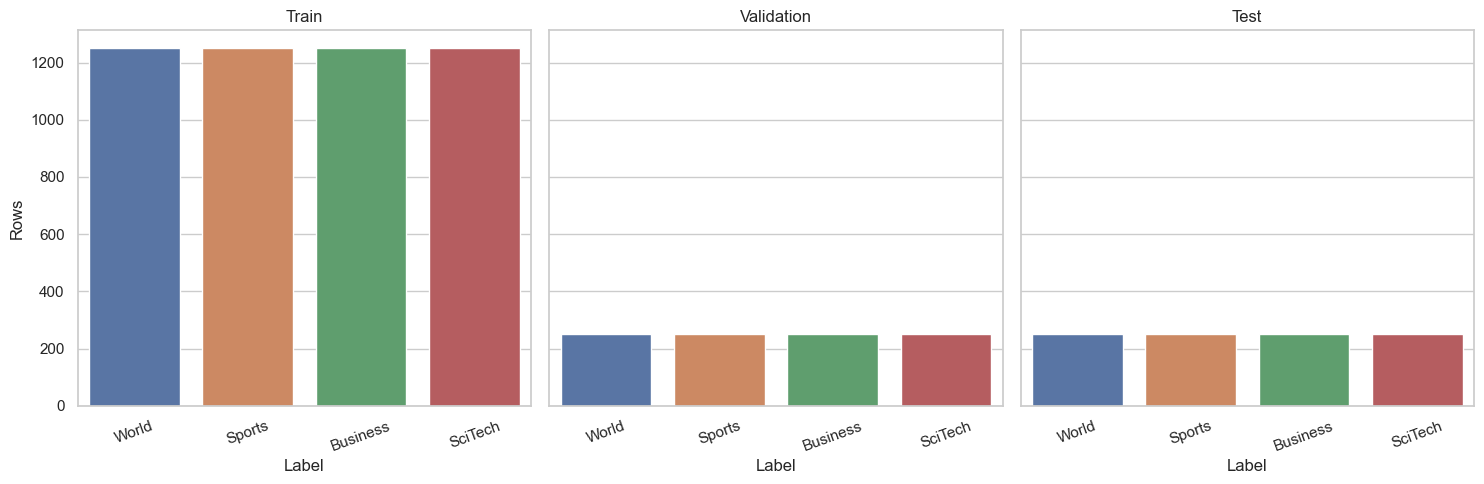

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for axis, data, title in zip(axes, [train, validation, test], ["Train", "Validation", "Test"]):
    counts = data["label"].value_counts().reindex(LABELS, fill_value=0)
    sns.barplot(x=counts.index, y=counts.values, ax=axis, hue=counts.index, palette="deep", legend=False)
    axis.set_title(title)
    axis.set_xlabel("Label")
    axis.set_ylabel("Rows")
    axis.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [6]:
train.head()

,text,label
0,Dotykové displeje jsou fenoménem dnešní doby. ...,SciTech
1,Diskriminace na pracovištích přetrvává vcelosv...,Business
2,Už sedm Čechů přišlo o život během letošní let...,World
3,Hokejisté Motoru České Budějovice potvrdili ve...,Sports
4,Vlády v kolínské automobilce TPCA se ujímá dos...,Business


## Task 1: TF-IDF

Pro reprezentaci textu použiji `TfidfVectorizer`. Následně vyzkouším dva klasické modely pro klasifikaci textu: `MultinomialNB` a `LogisticRegression`.

Modely natrénuji na `train` datech, porovnám jejich přesnost na `validation` splitu a na konci změřím finální přesnost na `test` splitu.

In [11]:
tfidf_NB = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB()),
])

tfidf_LR = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
])


In [16]:
tfidf_NB.fit(X_train, y_train)
tfidf_NB_predictions = tfidf_NB.predict(X_test)
tfidf_NB_accuracy = float(accuracy_score(y_test, tfidf_NB_predictions))
print(f"MultinomialNB accuracy: {tfidf_NB_accuracy:.4f}")

tfidf_LR.fit(X_train, y_train)
tfidf_LR_predictions = tfidf_LR.predict(X_test)
tfidf_LR_accuracy = float(accuracy_score(y_test, tfidf_LR_predictions))
print(f"LogisticRegression accuracy: {tfidf_LR_accuracy:.4f}")


MultinomialNB accuracy: 0.8300
LogisticRegression accuracy: 0.8160


## Baseline

Jako naši baseline použijeme `MultinomialNB`, který má nejvyšší přesnost na `test` datech, je vhodným výchozím bodem pro porovnání dalších modelů.

**Přesnost:** 83%

## Task 2: Sémantické Embeddings

V této části použiji předtrénovaný model `Seznam/simcse-dist-mpnet-czeng-cs-en` ze `sentence-transformers`. Texty z `train` a `test` splitu nejprve převedu na husté sémantické embeddingy a následně na nich natrénuji dva klasifikátory: `GaussianNB` a `LogisticRegression`.

Na konci opět změřím přesnost obou modelů na `test` splitu.

In [18]:
embedding_model = SentenceTransformer("Seznam/simcse-dist-mpnet-czeng-cs-en")

train_embeddings: np.ndarray = embedding_model.encode(
    X_train.tolist(),
    convert_to_numpy=True,
    show_progress_bar=True,
)
test_embeddings: np.ndarray = embedding_model.encode(
    X_test.tolist(),
    convert_to_numpy=True,
    show_progress_bar=True,
)


config.json:   0%|          | 0.00/582 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/97.4M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/97.3M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

In [20]:
embedding_NB = GaussianNB()
embedding_NB.fit(train_embeddings, y_train)
embedding_NB_predictions = embedding_NB.predict(test_embeddings)
embedding_NB_accuracy = float(accuracy_score(y_test, embedding_NB_predictions))
print(f"GaussianNB accuracy: {embedding_NB_accuracy:.4f}")

embedding_LR = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
embedding_LR.fit(train_embeddings, y_train)
embedding_LR_predictions = embedding_LR.predict(test_embeddings)
embedding_LR_accuracy = float(accuracy_score(y_test, embedding_LR_predictions))
print(f"LogisticRegression accuracy: {embedding_LR_accuracy:.4f}")


GaussianNB accuracy: 0.8040
LogisticRegression accuracy: 0.8460
